# CAPSTONE - PERSONAL LOAN

<br>

### **<font color="black">Note:</font>**

<br>


## Introduction

In this lab we will step through an end-to-end prediction process. Our data comes from the UCI Machine Learning Repository: [bank data](https://archive.ics.uci.edu/ml/datasets/Bank+Marketing)

The goal is binary classification; to predict whether a customer will purchase a banking product marketed over the phone.

## Scenario

You are a data analyst working for a Portuguese bank. The bank has recently run a campaign to attempt to sell a new product to customers over the phone. The product is a term deposit, where customers deposit their money for a fixed period of time for a fixed interest rate. They want to analyze the results of this campaign to understand what makes customers likely to buy this particular product. Your job as the data analyst is to explore the data and use machine learning to build a model to predict whether a customer is likely to buy.

<br>

### **<font color="red">Business process:</font>**
### **<font color="red">1. Bank call customer to sell to customer</font>**
### **<font color="red">2. If customer does not buy, effort is wasted</font>**
### **<font color="red">3. Hence use machine learning model to identify customers who will most likely buy before calling them</font>**
<br>

<br>

# **1. Import libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from scipy.stats import chi2_contingency
from IPython.display import display
from matplotlib.gridspec import GridSpec
from pandas.api.types import is_numeric_dtype
import statsmodels.api as sm
import shap

<br>

# **2. Read data**

In [3]:
df = pd.read_csv("Loan_default_orig.csv")
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [5]:
# Check for NULLs in each column
print(df.isnull().sum())

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64


In [7]:
# Check for NULLs in rows 
null_rows = df[df.isnull().any(axis=1)]
print(null_rows)

Empty DataFrame
Columns: [LoanID, Age, Income, LoanAmount, CreditScore, MonthsEmployed, NumCreditLines, InterestRate, LoanTerm, DTIRatio, Education, EmploymentType, MaritalStatus, HasMortgage, HasDependents, LoanPurpose, HasCoSigner, Default]
Index: []


In [9]:
# Check for duplicate rows
duplicates = df[df.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [LoanID, Age, Income, LoanAmount, CreditScore, MonthsEmployed, NumCreditLines, InterestRate, LoanTerm, DTIRatio, Education, EmploymentType, MaritalStatus, HasMortgage, HasDependents, LoanPurpose, HasCoSigner, Default]
Index: []


<br>

# **3. Drop features that cannot affect target, <font color='red'>from business process and experience</font>**

In [11]:
df = df.drop(columns=['HasCoSigner'])
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,0


<br>

# **4. Split into training dataset and testing dataset**

In [13]:
df_train, df_test = train_test_split(df, stratify=df['Default'], random_state=42)

In [15]:
df_train

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,Default
156648,PXK3XE0VUT,57,80124,170268,583,91,4,19.56,36,0.71,High School,Unemployed,Divorced,Yes,No,Other,0
28709,FE8UA22YSZ,65,122455,238302,529,47,4,3.14,48,0.53,Bachelor's,Full-time,Divorced,No,No,Other,0
139289,12NYGRUW92,33,64112,211382,545,55,4,5.16,36,0.21,Bachelor's,Self-employed,Divorced,No,No,Other,0
214508,1BIHTQ34EN,68,18013,42913,342,14,4,7.67,12,0.50,Bachelor's,Part-time,Divorced,Yes,No,Business,0
137518,XHRZ5VYSX2,43,50466,118541,637,109,3,19.74,12,0.34,Bachelor's,Full-time,Divorced,No,No,Other,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59108,MRFZSIQ2T3,18,115282,142016,601,50,3,3.43,36,0.36,Master's,Unemployed,Divorced,No,No,Business,0
71610,4H8QNIW1U4,67,39547,94145,383,82,4,3.32,48,0.80,PhD,Unemployed,Married,No,No,Auto,0
85645,SQDOP1N6XP,60,48470,29331,590,42,1,12.67,12,0.83,High School,Self-employed,Single,No,No,Auto,0
21010,ETLMBYVP7C,37,56697,76419,461,15,2,19.61,60,0.24,High School,Part-time,Divorced,Yes,Yes,Other,0


In [17]:
df_test

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,Default
131834,L02BCBCYJH,30,38632,216226,649,99,2,11.76,24,0.19,PhD,Unemployed,Single,No,Yes,Business,0
228947,28ACGD4221,23,135644,17941,494,12,3,14.20,12,0.59,Master's,Full-time,Divorced,No,No,Home,1
60842,LF1RSLLRDE,45,146036,99962,425,30,1,16.99,36,0.68,High School,Unemployed,Single,Yes,No,Education,0
80381,9IZ13RL175,28,119725,223883,839,21,1,18.64,12,0.36,Bachelor's,Unemployed,Married,Yes,No,Business,1
56260,PG0FMX2MUB,50,38772,144422,797,108,2,22.92,24,0.43,PhD,Self-employed,Married,Yes,No,Auto,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79832,YKUR9ZCGRR,63,22742,81575,777,93,2,15.52,36,0.20,Bachelor's,Self-employed,Divorced,No,No,Auto,0
120649,2EYD5LMRMM,25,120242,40549,431,97,2,20.81,36,0.10,Bachelor's,Part-time,Single,Yes,No,Education,1
64299,JSUDXP5UDV,60,26394,15670,543,48,4,3.05,24,0.70,High School,Unemployed,Divorced,No,Yes,Other,0
166839,NR88GIG14M,32,33862,117855,346,20,2,14.79,48,0.81,Bachelor's,Part-time,Divorced,No,No,Education,0


In [19]:
df_train['Default'].value_counts(dropna=False, normalize=True)

Default
0    0.88387
1    0.11613
Name: proportion, dtype: float64

In [21]:
df_test['Default'].value_counts(dropna=False, normalize=True)

Default
0    0.883876
1    0.116124
Name: proportion, dtype: float64

<br>

# **5. Function to describe numeric feature**

In [23]:
def numeric_describe(df):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios':[3, 1], 'wspace':0.2})
    df.plot.hist(ax=axes[0])
    df.plot.box(ax=axes[1])
    plt.show()

<br>

# **6. Function to describe non-numeric feature**

In [25]:
def non_numeric_describe(df):
    df1 = df.value_counts(dropna=False).reset_index()
    df2 = round(df.value_counts(normalize=True, dropna=False).reset_index()*100,2)
    df2 = df2.drop(df2.columns[0], axis=1)
    df3 = pd.concat([df1,df2], axis=1)

    if is_numeric_dtype(df3.iloc[:,0]):
        df3.iloc[:,0] = df3.iloc[:,0].round(0).astype('Int64').astype(str)
    
    fig = plt.figure(figsize=(13, 4))
    gs = GridSpec(1, 2, width_ratios=[1, 1])
    
    ax1 = fig.add_subplot(gs[0])
    ax1.axis('off')
    table = ax1.table(cellText=df3.values, colLabels=df3.columns, loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 2)

    ax2 = fig.add_subplot(gs[1])
    ax2.bar(df3.iloc[:,0], df3.iloc[:,2], color='skyblue')
    ax2.set_xticklabels(df3.iloc[:,0], rotation=45)

<br>

# **7. Exploratory data analysis on numeric features using (5)**

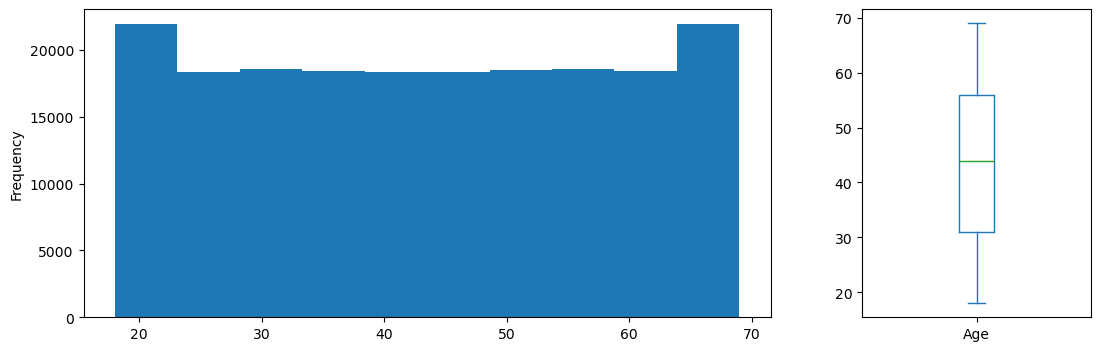

In [27]:
numeric_describe(df_train['Age'])

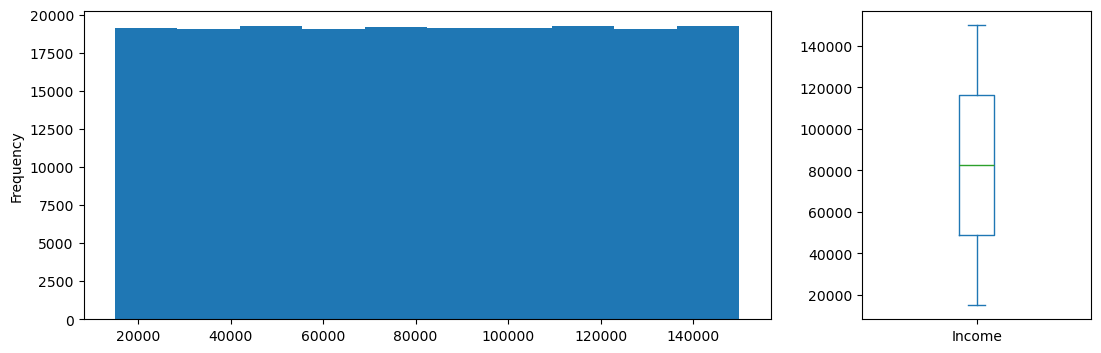

In [29]:
numeric_describe(df_train['Income'])

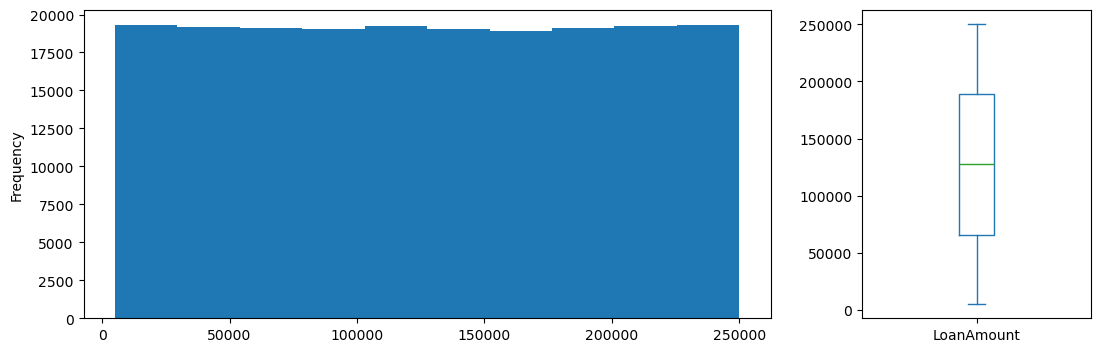

In [31]:
numeric_describe(df_train['LoanAmount'])

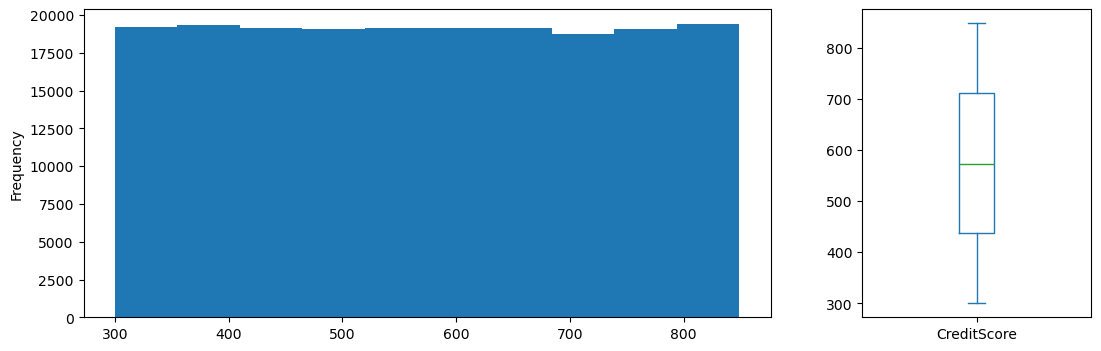

In [33]:
numeric_describe(df_train['CreditScore'])

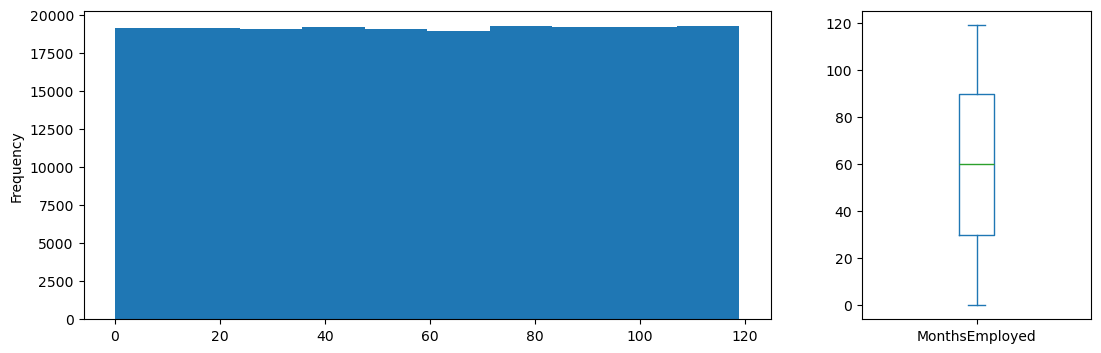

In [35]:
numeric_describe(df_train['MonthsEmployed'])

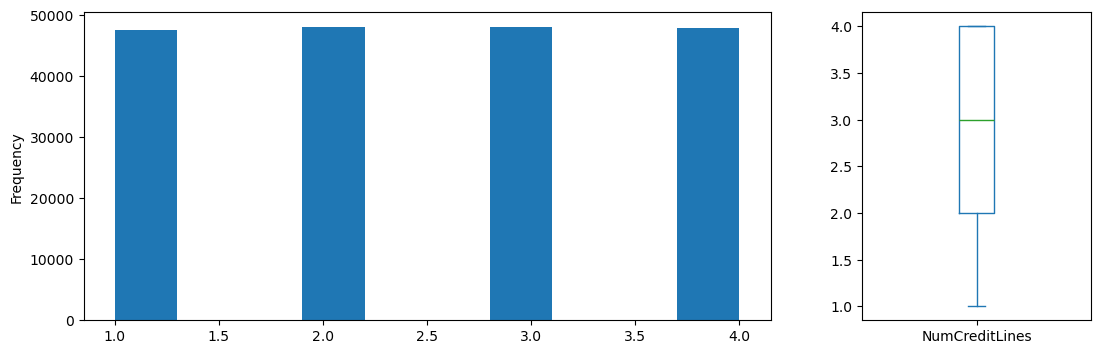

In [37]:
numeric_describe(df_train['NumCreditLines'])

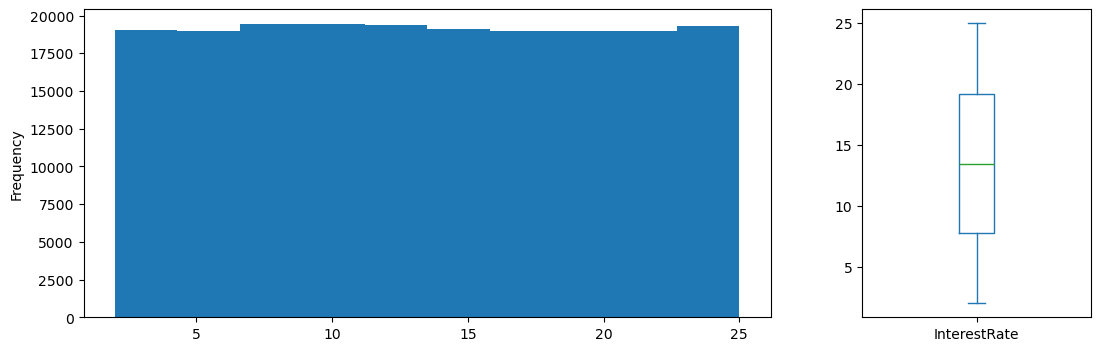

In [39]:
numeric_describe(df_train['InterestRate'])

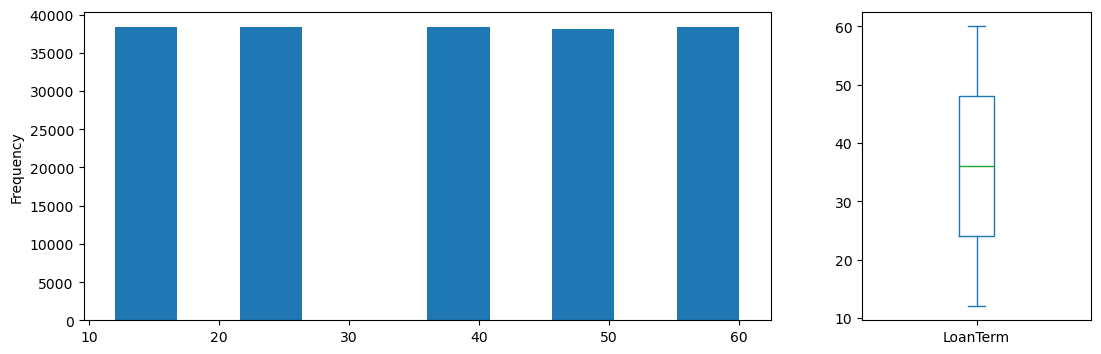

In [41]:
numeric_describe(df_train['LoanTerm'])

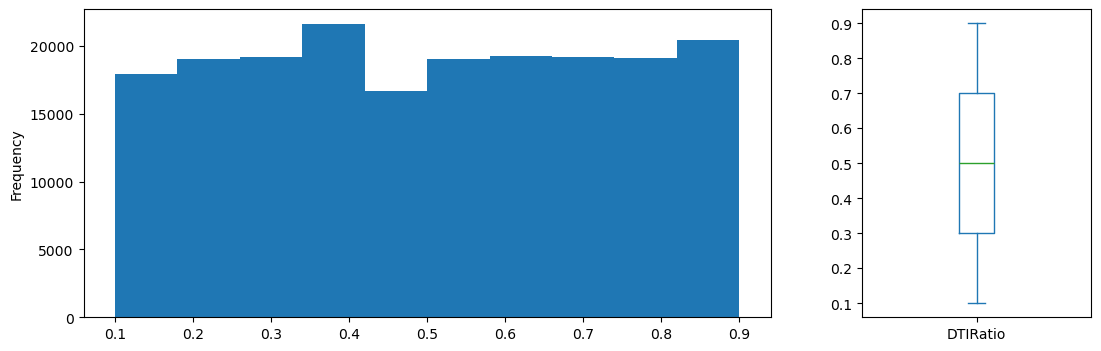

In [43]:
numeric_describe(df_train['DTIRatio'])

<br>

# **8. Exploratory data analysis on non-numeric features using (6)**

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


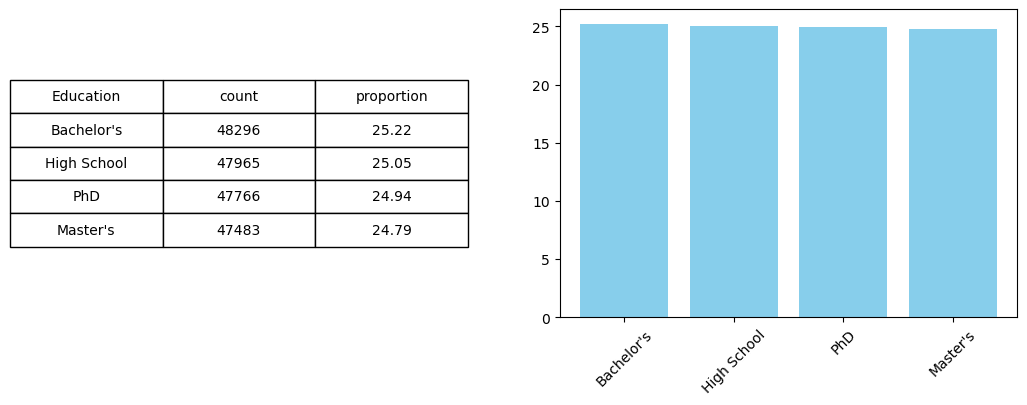

In [45]:
non_numeric_describe(df_train['Education'])

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


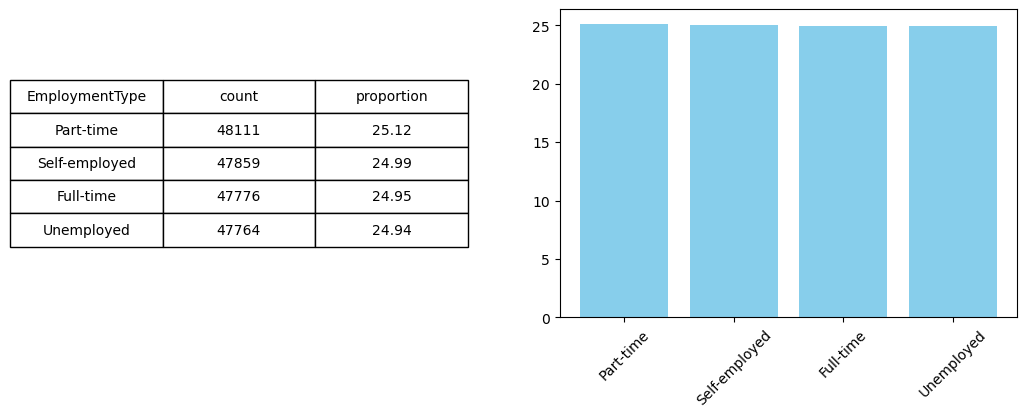

In [47]:
non_numeric_describe(df_train['EmploymentType'])

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


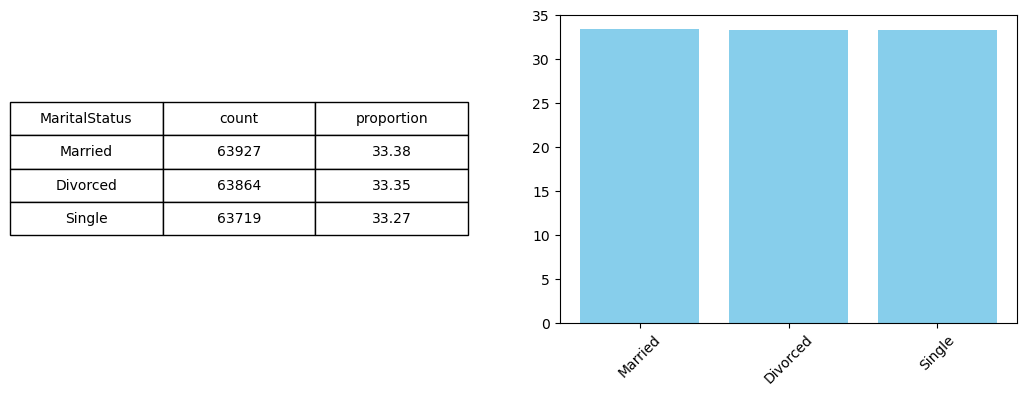

In [49]:
non_numeric_describe(df_train['MaritalStatus'])

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


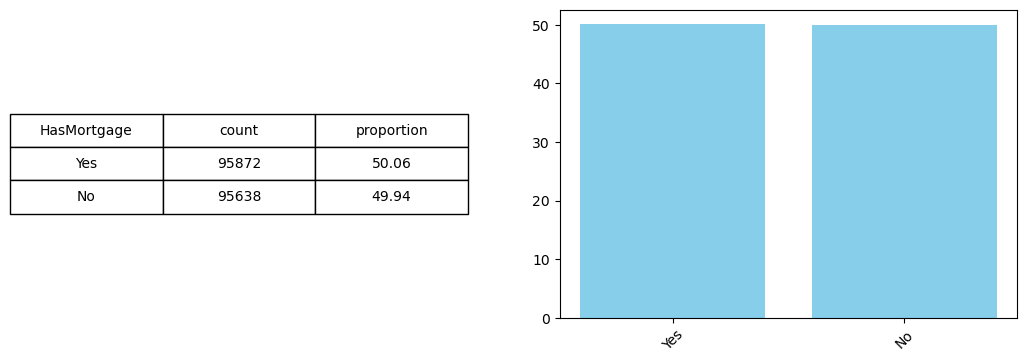

In [51]:
non_numeric_describe(df_train['HasMortgage'])

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


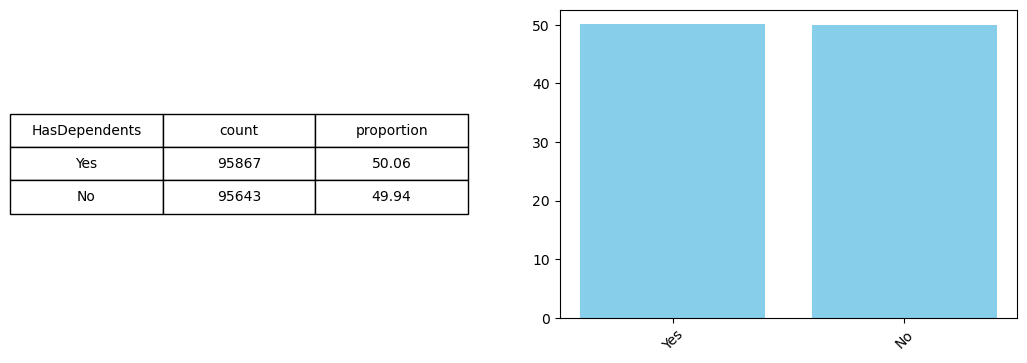

In [53]:
non_numeric_describe(df_train['HasDependents'])

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


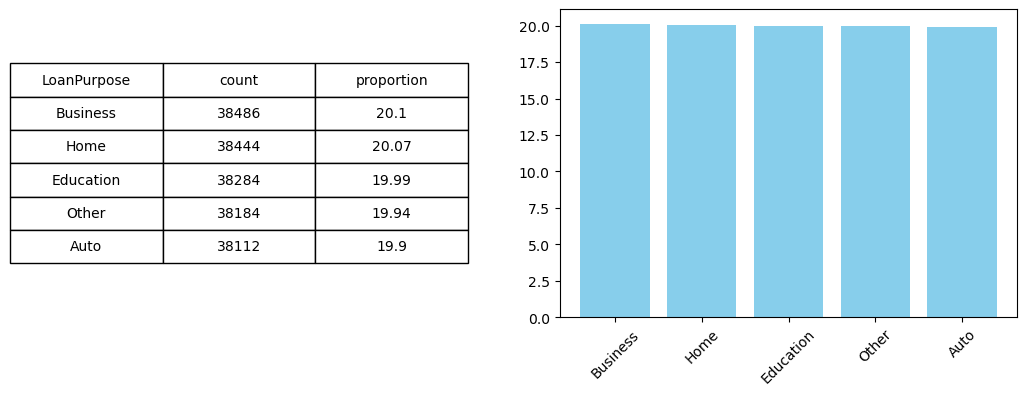

In [55]:
non_numeric_describe(df_train['LoanPurpose'])

C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0    0
1    1
Name: Default, dtype: object' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df3.iloc[:,0] = df3.iloc[:,0].round(0).astype('Int64').astype(str)
C:\Users\USER\AppData\Local\Temp\ipykernel_7232\54429179.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df3.iloc[:,0], rotation=45)


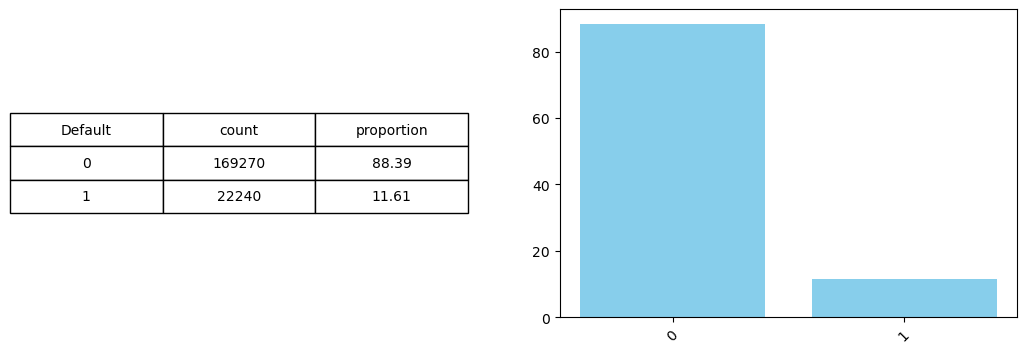

In [57]:
non_numeric_describe(df_train['Default'])

#### **Class is imbalanced. Hence will need to over-sample <font color='red'>later</font>.**
<br>


# **9.1. Data manipulation on df_train. Must do the same on df_test <font color='red'>later</font>.**

In [59]:
df_train['Default'] = df_train['Default'].astype(bool)

In [61]:
df_train.dtypes

LoanID             object
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education          object
EmploymentType     object
MaritalStatus      object
HasMortgage        object
HasDependents      object
LoanPurpose        object
Default              bool
dtype: object

In [63]:
df_train

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,Default
156648,PXK3XE0VUT,57,80124,170268,583,91,4,19.56,36,0.71,High School,Unemployed,Divorced,Yes,No,Other,False
28709,FE8UA22YSZ,65,122455,238302,529,47,4,3.14,48,0.53,Bachelor's,Full-time,Divorced,No,No,Other,False
139289,12NYGRUW92,33,64112,211382,545,55,4,5.16,36,0.21,Bachelor's,Self-employed,Divorced,No,No,Other,False
214508,1BIHTQ34EN,68,18013,42913,342,14,4,7.67,12,0.50,Bachelor's,Part-time,Divorced,Yes,No,Business,False
137518,XHRZ5VYSX2,43,50466,118541,637,109,3,19.74,12,0.34,Bachelor's,Full-time,Divorced,No,No,Other,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59108,MRFZSIQ2T3,18,115282,142016,601,50,3,3.43,36,0.36,Master's,Unemployed,Divorced,No,No,Business,False
71610,4H8QNIW1U4,67,39547,94145,383,82,4,3.32,48,0.80,PhD,Unemployed,Married,No,No,Auto,False
85645,SQDOP1N6XP,60,48470,29331,590,42,1,12.67,12,0.83,High School,Self-employed,Single,No,No,Auto,False
21010,ETLMBYVP7C,37,56697,76419,461,15,2,19.61,60,0.24,High School,Part-time,Divorced,Yes,Yes,Other,False


<br>

# **One last check**

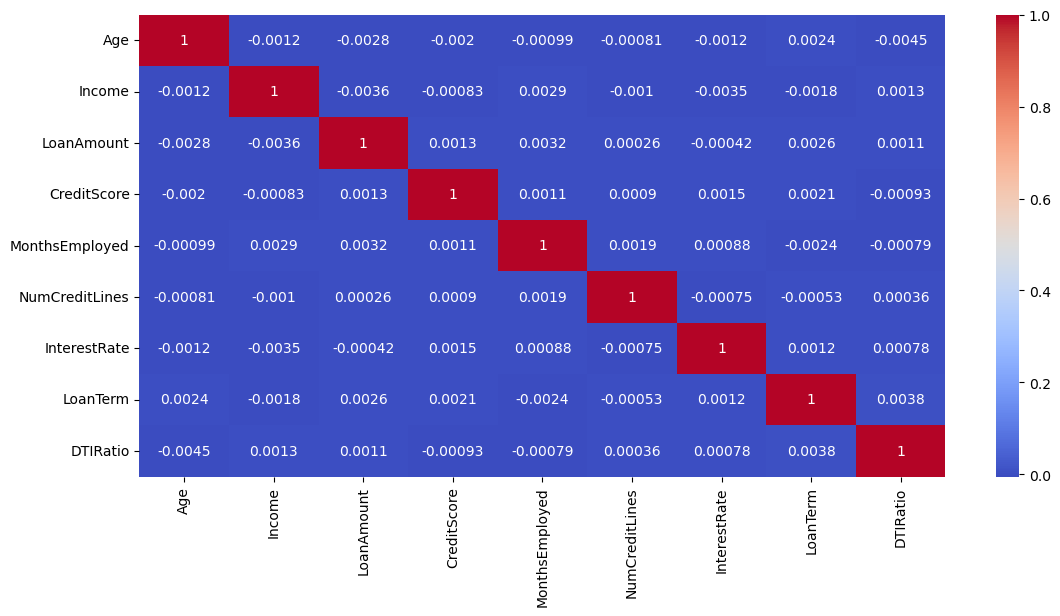

In [65]:
"""
This is for numeric features
"""
plt.figure(figsize=(13, 6))
sns.heatmap(df_train[['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']].corr(), annot=True, cmap='coolwarm')
plt.show()

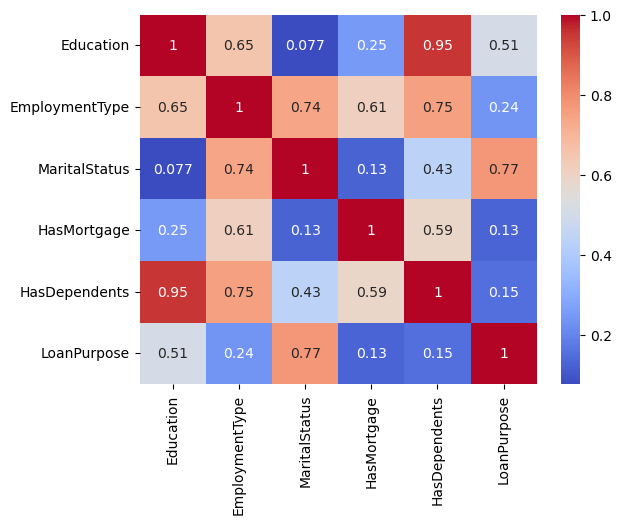

In [67]:
"""
This is for non-numeric features
"""

non_numeric_columns = ['Education','EmploymentType','MaritalStatus','HasMortgage','HasDependents','LoanPurpose']
p_value_matrix = pd.DataFrame(index=non_numeric_columns, columns=non_numeric_columns)

for col_1 in non_numeric_columns:
    for col_2 in non_numeric_columns:
        if col_1 == col_2:
            p_value_matrix.loc[col_1, col_2] = 1
        else:
            contingency_table = pd.crosstab(df_train[col_1], df_train[col_2])
            chi2, p, dof, expected = chi2_contingency(contingency_table)
            p_value_matrix.loc[col_1, col_2] = round(p, 4)

p_value_matrix = p_value_matrix.astype(float)

sns.heatmap(p_value_matrix, annot=True, cmap='coolwarm')
plt.show()

<br>

# **9.2. One hot encoding on df_train. Must do the same on df_test <font color='red'>later</font>.**

In [69]:
"""
This is for non-numeric features
"""

non_numeric_columns = ['Education','EmploymentType','MaritalStatus','HasMortgage','HasDependents','LoanPurpose']
encoder_1 = OneHotEncoder(sparse_output=False, drop='first')
encoder_1_df = encoder_1.fit_transform(df_train[non_numeric_columns])
encoder_1_df = pd.DataFrame(encoder_1_df, columns=encoder_1.get_feature_names_out(non_numeric_columns))
encoder_1_df

,Education_High School,Education_Master's,Education_PhD,EmploymentType_Part-time,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other
0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191505,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
191506,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
191507,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
191508,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0


<br>

# **9.3. Scaling on df_train. Must do the same on df_test <font color='red'>later</font>.**

In [71]:
"""
This is for numeric features
"""

numeric_columns = ['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']
scaler_1 = MinMaxScaler()
scaler_1_df = scaler_1.fit_transform(df_train[numeric_columns])
scaler_1_df = pd.DataFrame(scaler_1_df, columns=df_train[['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']].columns)
scaler_1_df

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
0,0.764706,0.482404,0.674566,0.515483,0.764706,1.000000,0.763478,0.50,0.7625
1,0.921569,0.795969,0.952257,0.417122,0.394958,1.000000,0.049565,0.75,0.5375
2,0.294118,0.363795,0.842379,0.446266,0.462185,1.000000,0.137391,0.50,0.1375
3,0.980392,0.022319,0.154748,0.076503,0.117647,1.000000,0.246522,0.00,0.5000
4,0.490196,0.262713,0.463435,0.613843,0.915966,0.666667,0.771304,0.00,0.3000
...,...,...,...,...,...,...,...,...,...
191505,0.000000,0.742835,0.559251,0.548270,0.420168,0.666667,0.062174,0.50,0.3250
191506,0.960784,0.181831,0.363859,0.151184,0.689076,1.000000,0.057391,0.75,0.8750
191507,0.823529,0.247928,0.099311,0.528233,0.352941,0.000000,0.463913,0.00,0.9125
191508,0.372549,0.308869,0.291507,0.293260,0.126050,0.333333,0.765652,1.00,0.1750


<br>

# **9.4. Combine into df_train_final. Must do the same for df_test_final <font color='red'>later</font>.**

In [73]:
df_train_final = pd.concat([encoder_1_df, scaler_1_df, df_train['Default'].reset_index(drop=True)], axis=1)
df_train_final

,Education_High School,Education_Master's,Education_PhD,EmploymentType_Part-time,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,...,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.764706,0.482404,0.674566,0.515483,0.764706,1.000000,0.763478,0.50,0.7625,False
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.921569,0.795969,0.952257,0.417122,0.394958,1.000000,0.049565,0.75,0.5375,False
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.294118,0.363795,0.842379,0.446266,0.462185,1.000000,0.137391,0.50,0.1375,False
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.980392,0.022319,0.154748,0.076503,0.117647,1.000000,0.246522,0.00,0.5000,False
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.490196,0.262713,0.463435,0.613843,0.915966,0.666667,0.771304,0.00,0.3000,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191505,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.000000,0.742835,0.559251,0.548270,0.420168,0.666667,0.062174,0.50,0.3250,False
191506,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.960784,0.181831,0.363859,0.151184,0.689076,1.000000,0.057391,0.75,0.8750,False
191507,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.823529,0.247928,0.099311,0.528233,0.352941,0.000000,0.463913,0.00,0.9125,False
191508,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.372549,0.308869,0.291507,0.293260,0.126050,0.333333,0.765652,1.00,0.1750,False


In [75]:
X_train = df_train_final.drop(columns=['Default'])
y_train = df_train_final['Default']
actual_y_train_category = y_train

<br>

# **10.1. Model 1 - Logistic regression fit + predict on df_train_final**

In [77]:
lr_model = LogisticRegression(class_weight='balanced')
lr_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced')

In [79]:
predicted_y_train_category = lr_model.predict(X_train)
predicted_y_train_probability = lr_model.predict_proba(X_train)[:, 1]

In [81]:
predicted_y_train_probability[:5]

array([0.52881038, 0.21182984, 0.6192592 , 0.38852823, 0.48106932])

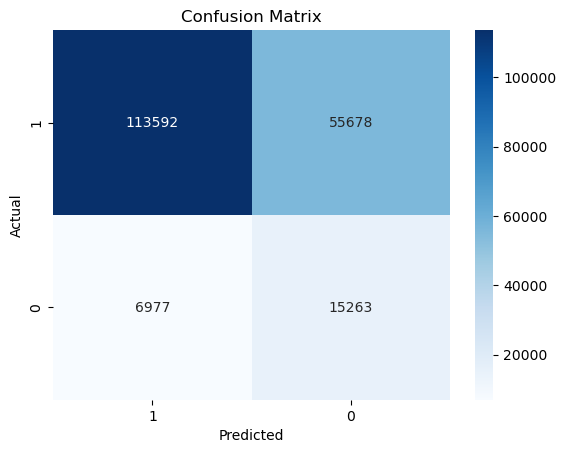

In [83]:
cm = confusion_matrix(actual_y_train_category, predicted_y_train_category)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[1,0], yticklabels=[1,0])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [85]:
print("Accuracy :", accuracy_score(actual_y_train_category, predicted_y_train_category))
print("Precision :", precision_score(actual_y_train_category, predicted_y_train_category))
print("Recall :", recall_score(actual_y_train_category, predicted_y_train_category))

Accuracy : 0.6728369275755836
Precision : 0.2151506181192822
Recall : 0.6862859712230216


<br>

# **10.2. Model 2 - K nearest neighbours fit + predict on df_train_final**

In [87]:
knn_model = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn_model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3, weights='distance')

In [89]:
predicted_y_train_category = knn_model.predict(X_train)
predicted_y_train_probability = knn_model.predict_proba(X_train)[:, 1]

In [91]:
predicted_y_train_probability[:50].round(3)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 1., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [93]:
predicted_y_train_category[:50]

array([False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False,  True, False,  True, False, False, False, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False])

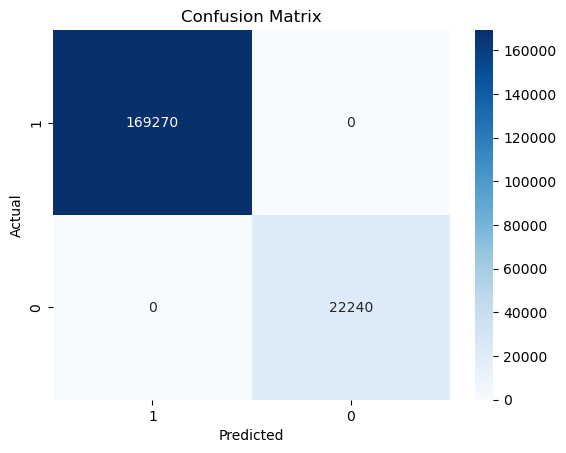

In [95]:
cm = confusion_matrix(actual_y_train_category, predicted_y_train_category)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[1,0], yticklabels=[1,0])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [97]:
print("Accuracy :", accuracy_score(actual_y_train_category, predicted_y_train_category))
print("Precision :", precision_score(actual_y_train_category, predicted_y_train_category))
print("Recall :", recall_score(actual_y_train_category, predicted_y_train_category))

Accuracy : 1.0
Precision : 1.0
Recall : 1.0


<br>

# **11.2. One hot encoding on df_test. <font color='red'>From 9.2.</font>**

In [99]:
"""
This is for non-numeric features
"""

non_numeric_columns = ['Education','EmploymentType','MaritalStatus','HasMortgage','HasDependents','LoanPurpose']
encoder_2_df = encoder_1.transform(df_test[non_numeric_columns])
encoder_2_df = pd.DataFrame(encoder_2_df, columns=encoder_1.get_feature_names_out(non_numeric_columns))
encoder_2_df

,Education_High School,Education_Master's,Education_PhD,EmploymentType_Part-time,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63832,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
63833,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
63834,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
63835,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


<br>

# **11.3. Scaling on df_test. <font color='red'>From 9.3.</font>**

In [101]:
"""
This is for numeric features
"""

numeric_columns = ['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']
scaler_2_df = scaler_1.transform(df_test[numeric_columns])
scaler_2_df = pd.DataFrame(scaler_2_df, columns=df_test[['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']].columns)
scaler_2_df

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
0,0.235294,0.175053,0.862150,0.635701,0.831933,0.333333,0.424348,0.25,0.1125
1,0.098039,0.893666,0.052821,0.353370,0.100840,0.666667,0.530435,0.00,0.6125
2,0.529412,0.970644,0.387602,0.227687,0.252101,0.000000,0.651739,0.50,0.7250
3,0.196078,0.775746,0.893404,0.981785,0.176471,0.000000,0.723478,0.00,0.3250
4,0.627451,0.176090,0.569072,0.905282,0.907563,0.333333,0.909565,0.25,0.4125
...,...,...,...,...,...,...,...,...,...
63832,0.882353,0.057349,0.312552,0.868852,0.781513,0.333333,0.587826,0.50,0.1250
63833,0.137255,0.779576,0.145099,0.238616,0.815126,0.333333,0.817826,0.50,0.0000
63834,0.823529,0.084401,0.043551,0.442623,0.403361,1.000000,0.045652,0.25,0.7500
63835,0.274510,0.139720,0.460635,0.083789,0.168067,0.333333,0.556087,0.75,0.8875


<br>

# **11.4. Combine into df_test_final. <font color='red'>From 9.4.</font>**

In [103]:
df_test_final = pd.concat([encoder_2_df, scaler_2_df, df_test['Default'].reset_index(drop=True)], axis=1)
df_test_final

,Education_High School,Education_Master's,Education_PhD,EmploymentType_Part-time,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,...,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.235294,0.175053,0.862150,0.635701,0.831933,0.333333,0.424348,0.25,0.1125,0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.098039,0.893666,0.052821,0.353370,0.100840,0.666667,0.530435,0.00,0.6125,1
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.529412,0.970644,0.387602,0.227687,0.252101,0.000000,0.651739,0.50,0.7250,0
3,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.196078,0.775746,0.893404,0.981785,0.176471,0.000000,0.723478,0.00,0.3250,1
4,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.627451,0.176090,0.569072,0.905282,0.907563,0.333333,0.909565,0.25,0.4125,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63832,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.882353,0.057349,0.312552,0.868852,0.781513,0.333333,0.587826,0.50,0.1250,0
63833,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.137255,0.779576,0.145099,0.238616,0.815126,0.333333,0.817826,0.50,0.0000,1
63834,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.823529,0.084401,0.043551,0.442623,0.403361,1.000000,0.045652,0.25,0.7500,0
63835,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.274510,0.139720,0.460635,0.083789,0.168067,0.333333,0.556087,0.75,0.8875,0


In [105]:
X_test = df_test_final.drop(columns=['Default'])
y_test = df_test_final['Default']
actual_y_test_category = y_test

<br>

# **12.1. Model 1 - Logistic regression predict on df_test_final**

In [107]:
predicted_y_test_category = lr_model.predict(X_test)
predicted_y_test_probability = lr_model.predict_proba(X_test)[:, 1]

In [109]:
list(predicted_y_test_probability[:5])

[0.5900570559779259,
 0.5130873105823628,
 0.49450022775607705,
 0.7259767868536936,
 0.40530609701470194]

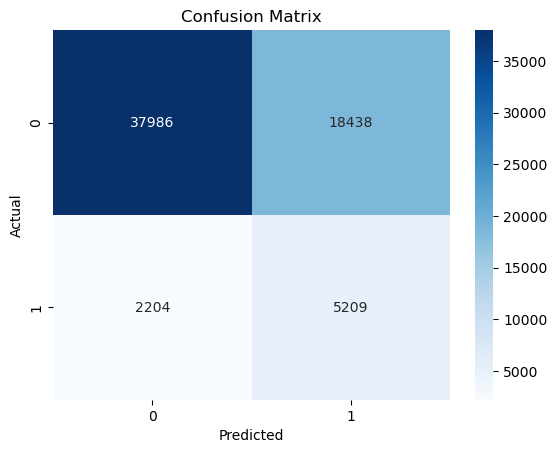

In [111]:
cm = confusion_matrix(actual_y_test_category, predicted_y_test_category)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [113]:
print("Accuracy :", accuracy_score(actual_y_test_category, predicted_y_test_category))
print("Precision :", precision_score(actual_y_test_category, predicted_y_test_category))
print("Recall :", recall_score(actual_y_test_category, predicted_y_test_category))

Accuracy : 0.6766452057584159
Precision : 0.220281642491648
Recall : 0.7026844732227169


<br>

# **Entry by bank officer from customer data**

In [115]:
X_train.columns

Index(['Education_High School', 'Education_Master's', 'Education_PhD',
       'EmploymentType_Part-time', 'EmploymentType_Self-employed',
       'EmploymentType_Unemployed', 'MaritalStatus_Married',
       'MaritalStatus_Single', 'HasMortgage_Yes', 'HasDependents_Yes',
       'LoanPurpose_Business', 'LoanPurpose_Education', 'LoanPurpose_Home',
       'LoanPurpose_Other', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio'],
      dtype='object')

In [233]:
"""
X_input_1 = {'Education_High School':1,
             'Education_Master\'s':0,
             'Education_PhD':0,
             'EmploymentType_Part-time':0,
             'EmploymentType_Self-employed':0,
             'EmploymentType_Unemployed':1,
             'MaritalStatus_Married':1,
             'MaritalStatus_Single':0,
             'HasMortgage_Yes':0,
             'HasDependents_Yes':1,
             'LoanPurpose_Business':1,
             'LoanPurpose_Education':0,
             'LoanPurpose_Home':0,
             'LoanPurpose_Other':0,
             'Age':80,
             'Income':5,
             'LoanAmount':2000,
             'CreditScore':300,
             'MonthsEmployed':0,
             'NumCreditLines':0,
             'InterestRate':4.8,
             'LoanTerm':24,
             'DTIRatio':0.1}
X_input_2 = pd.DataFrame([X_input_1])
prediction = lr_model.predict(X_input_2)[0]
prediction_prob = list(lr_model.predict_proba(X_input_2)[:,1])[0].round(3)

if prediction == 1:
    print("True Default with probability ", prediction_prob)
else:
    print("No Default with probability ", prediction_prob)
"""

True Default with probability  1.0


In [117]:
# ----------------------------------------------------------------------------
# This is where to bank officer will enter the values for the model to predict
# ----------------------------------------------------------------------------

X_input_1 = {'Education':      'High School',
             'EmploymentType': 'Part-time',
             'MaritalStatus':  'Married',
             'HasMortgage':    'Yes',
             'HasDependents':  'Yes',
             'LoanPurpose':    'Business',
             'Age':            30,
             'Income':         0,
             'LoanAmount':     20000,
             'CreditScore':    0,
             'MonthsEmployed': 0,
             'NumCreditLines': 3,
             'InterestRate':   4.8,
             'LoanTerm':       24,
             'DTIRatio':       0.1
            }

X_input_2 = pd.DataFrame([X_input_1])

non_numeric_columns = ['Education','EmploymentType','MaritalStatus','HasMortgage','HasDependents','LoanPurpose']
encoder_2_df = encoder_1.transform(X_input_2[non_numeric_columns])
encoder_2_df = pd.DataFrame(encoder_2_df, columns=encoder_1.get_feature_names_out(non_numeric_columns))

numeric_columns = ['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']
scaler_2_df = scaler_1.transform(X_input_2[numeric_columns])
scaler_2_df = pd.DataFrame(scaler_2_df, columns=X_input_2[['Age','Income','LoanAmount','CreditScore','MonthsEmployed','NumCreditLines','InterestRate','LoanTerm','DTIRatio']].columns)

X_input_final = pd.concat([encoder_2_df, scaler_2_df], axis=1)

predicted_y_test_category = lr_model.predict(X_input_final)
predicted_y_test_probability = lr_model.predict_proba(X_input_final)[:, 1]

print(predicted_y_test_category)
print(predicted_y_test_probability)

[ True]
[0.66949984]


<br>

# **12.2. Model 2 - K nearest neighbours predict on df_test_final**

In [119]:
predicted_y_test_category = knn_model.predict(X_test)
predicted_y_test_probability = knn_model.predict_proba(X_test)[:, 1]

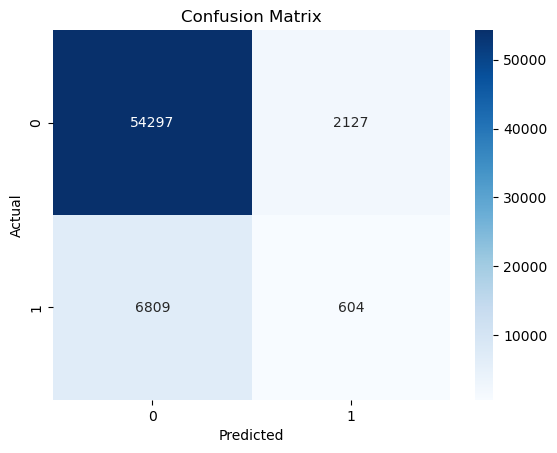

In [121]:
cm = confusion_matrix(actual_y_test_category, predicted_y_test_category)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [123]:
print("Accuracy :", accuracy_score(actual_y_test_category, predicted_y_test_category))
print("Precision :", precision_score(actual_y_test_category, predicted_y_test_category))
print("Recall :", recall_score(actual_y_test_category, predicted_y_test_category))

Accuracy : 0.8600184845779094
Precision : 0.22116440864152326
Recall : 0.08147848374477269


<br>

# **THE END**

<br>

# **SHAP (SHapley Additive exPlanations)**

  0%|          | 0/10 [00:00<?, ?it/s]

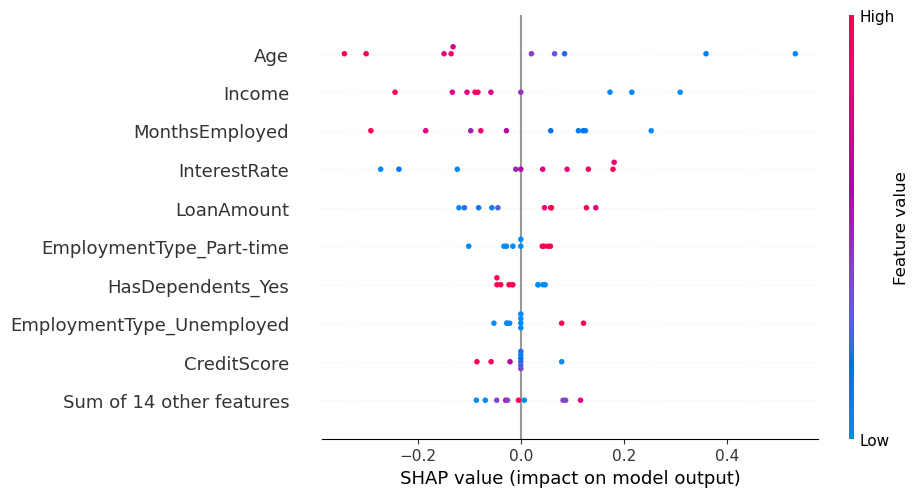

In [125]:
n_samples = 10
random_indices = np.random.choice(X_train.shape[0], size=n_samples, replace=False)
X_train_subset = X_train.iloc[random_indices]

explainer = shap.KernelExplainer(lr_model.predict, X_train_subset)
shap_values = explainer(X_train_subset)
shap.plots.beeswarm(shap_values)

  0%|          | 0/10 [00:00<?, ?it/s]

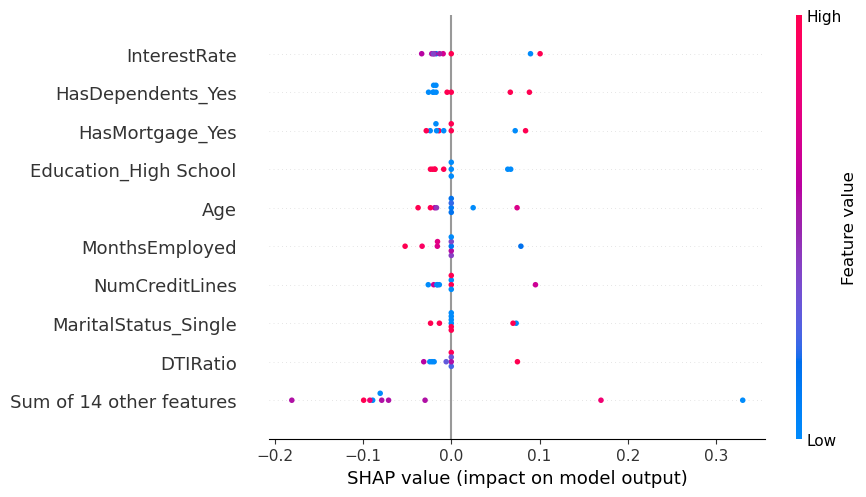

In [127]:
n_samples = 10
random_indices = np.random.choice(X_train.shape[0], size=n_samples, replace=False)
X_train_subset = X_train.iloc[random_indices]

explainer = shap.KernelExplainer(knn_model.predict, X_train_subset)
shap_values = explainer(X_train_subset)
shap.plots.beeswarm(shap_values)